# Soft Computing Mini Project 2

# Title: Hopfield Network as an Associative Memory

- Name_Abhinav Bhardwaj
- SystemID_2026320015

This notebook:
- stores 5x5 binary letter patterns using the **Hebbian learning rule**
- recalls them from noisy versions using **asynchronous updates**
- tracks the **energy function** (it never increases during recall)
- tests how recall accuracy changes with noise and with the number of stored patterns

**Requirements:** `numpy`, `matplotlib`

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## 1. Patterns

Each letter is a 5x5 grid. A filled pixel (`#`) is `+1` and an empty pixel (`.`) is `-1`.

In [2]:
LETTERS = {
    "A": ["..#..",
          ".#.#.",
          "#####",
          "#...#",
          "#...#"],
    "L": ["#....",
          "#....",
          "#....",
          "#....",
          "#####"],
    "T": ["#####",
          "..#..",
          "..#..",
          "..#..",
          "..#.."],
}


def to_vec(rows):
    """Convert ['#..', ...] into a flat vector of +1 (on) / -1 (off)."""
    return np.array([1 if ch == "#" else -1 for r in rows for ch in r])

## 2. The Hopfield network

- **Training (Hebbian rule):** $W = \frac{1}{N}\sum_p p\,p^T$, with the diagonal set to zero.
- **Energy:** $E(s) = -\frac{1}{2}\, s^T W s$
- **Recall:** neurons are updated one at a time in random order, $s_i \leftarrow \operatorname{sign}\left(\sum_j W_{ij}s_j\right)$, until no neuron changes.

In [3]:
class Hopfield:
    def __init__(self, n):
        self.n = n
        self.W = np.zeros((n, n))

    def train(self, patterns):
        """Hebbian rule: W = (1/N) * sum(p p^T), zero diagonal."""
        P = np.array(patterns)
        self.W = (P.T @ P) / self.n
        np.fill_diagonal(self.W, 0)

    def energy(self, s):
        return -0.5 * s @ self.W @ s

    def recall(self, state, max_sweeps=20):
        """Asynchronous updates in random order until nothing changes."""
        s = state.copy()
        energies = [self.energy(s)]
        for _ in range(max_sweeps):
            changed = False
            for i in rng.permutation(self.n):
                new = 1 if self.W[i] @ s >= 0 else -1
                if new != s[i]:
                    s[i] = new
                    changed = True
                    energies.append(self.energy(s))
            if not changed:
                break
        return s, energies


def add_noise(p, frac):
    """Flip a fraction of the bits."""
    p = p.copy()
    idx = rng.choice(len(p), size=int(round(frac * len(p))), replace=False)
    p[idx] *= -1
    return p

## 3. Experiment 1: Recalling letters from noisy input

Each stored letter has 20% of its pixels flipped (5 of 25), then the network tries to recover it.

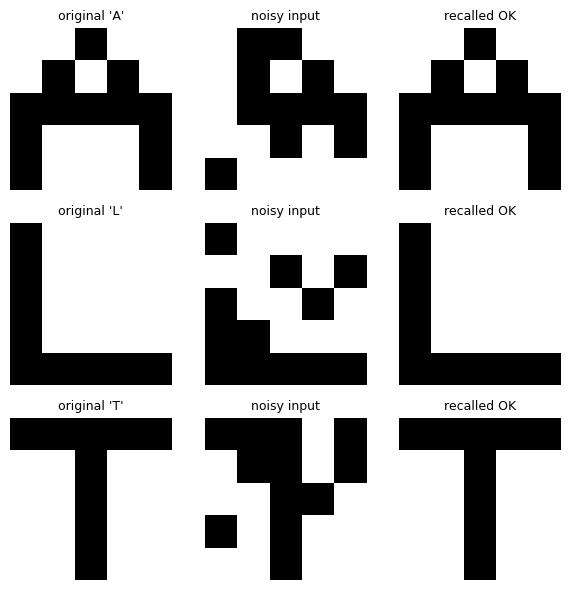

In [4]:
def experiment_recall():
    names = list(LETTERS)
    pats = [to_vec(LETTERS[k]) for k in names]
    net = Hopfield(25)
    net.train(pats)

    fig, axes = plt.subplots(len(names), 3, figsize=(6, 2 * len(names)))
    for r, (name, p) in enumerate(zip(names, pats)):
        noisy = add_noise(p, 0.2)
        out, _ = net.recall(noisy)
        ok = np.array_equal(out, p)
        for c, (img, title) in enumerate(
                [(p, f"original '{name}'"), (noisy, "noisy input"),
                 (out, "recalled " + ("OK" if ok else "WRONG"))]):
            axes[r, c].imshow(img.reshape(5, 5), cmap="gray_r", vmin=-1, vmax=1)
            axes[r, c].set_title(title, fontsize=9)
            axes[r, c].axis("off")
    plt.tight_layout()
    plt.savefig("recall_results.png", dpi=130)
    plt.show()


experiment_recall()

## 4. Experiment 2: Energy during recall

The energy decreases (or stays the same) with every flip. This is why the network always settles into a stable state.

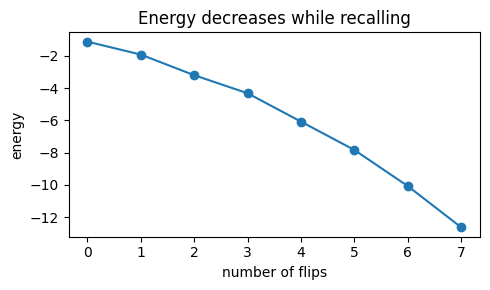

In [5]:
def experiment_energy():
    p = to_vec(LETTERS["A"])
    net = Hopfield(25)
    net.train([to_vec(v) for v in LETTERS.values()])
    _, e = net.recall(add_noise(p, 0.28))
    plt.figure(figsize=(5, 3))
    plt.plot(e, marker="o")
    plt.xlabel("number of flips")
    plt.ylabel("energy")
    plt.title("Energy decreases while recalling")
    plt.tight_layout()
    plt.savefig("energy_curve.png", dpi=130)
    plt.show()


experiment_energy()

## 5. Experiment 3: Storage capacity

Random patterns are stored in a 100-neuron network. Theory predicts reliable recall only up to about $0.138\,N$ patterns.

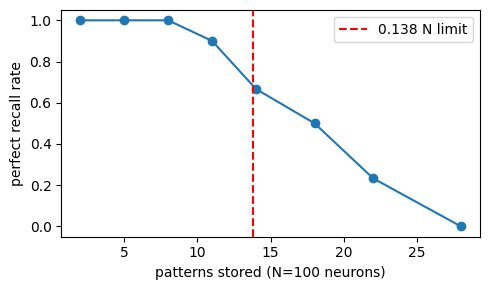

In [6]:
def experiment_capacity(n=100, trials=30):
    counts = [2, 5, 8, 11, 14, 18, 22, 28]
    acc = []
    for k in counts:
        good = 0
        for _ in range(trials):
            pats = rng.choice([-1, 1], size=(k, n))
            net = Hopfield(n)
            net.train(pats)
            out, _ = net.recall(add_noise(pats[0], 0.05))
            good += np.array_equal(out, pats[0])
        acc.append(good / trials)
    plt.figure(figsize=(5, 3))
    plt.plot(counts, acc, marker="o")
    plt.axvline(0.138 * n, color="r", ls="--", label="0.138 N limit")
    plt.xlabel(f"patterns stored (N={n} neurons)")
    plt.ylabel("perfect recall rate")
    plt.legend()
    plt.tight_layout()
    plt.savefig("capacity.png", dpi=130)
    plt.show()


experiment_capacity()

## 6. Experiment 4: Noise tolerance

How often is a stored letter recovered perfectly as more of its pixels are flipped?

In [7]:
def experiment_noise_tolerance(trials=50):
    pats = [to_vec(v) for v in LETTERS.values()]
    net = Hopfield(25)
    net.train(pats)
    levels = [0.0, 0.04, 0.08, 0.12, 0.16, 0.20, 0.30, 0.40]
    print("Noise level -> recall rate (3 letters stored)")
    for lv in levels:
        good = 0
        for _ in range(trials):
            i = rng.integers(len(pats))
            out, _ = net.recall(add_noise(pats[i], lv))
            good += np.array_equal(out, pats[i])
        print(f"  {lv:4.0%}  ->  {good / trials:5.0%}")


experiment_noise_tolerance()

Noise level -> recall rate (3 letters stored)
    0%  ->   100%
    4%  ->   100%
    8%  ->   100%
   12%  ->   100%
   16%  ->    92%
   20%  ->    96%
   30%  ->    68%
   40%  ->    42%


## Conclusion

- The Hopfield network recovers stored patterns from corrupted inputs, so it works as a content-addressable memory.
- Recall always converges because every update lowers or keeps the energy.
- Performance drops as noise increases and as more patterns are stored. Beyond roughly $0.138\,N$ patterns, recall becomes unreliable.